# Feature Selection and Image Classification

Compare greedy feature subset search on digit data and supervised flower classification using dense neural networks and pretrained convolutional architectures.

## Feature Conditioning with Gaussian Naive Bayes

Investigate how the selected input features affect the correct classification rate (CCR) of a Gaussian Naive Bayes classifier.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

### TinyMNIST data

Load 5,000 training and 2,500 test observations, each with 196 features, and their labels from the four CSV files under `TinyMNIST/`.

In [ ]:
train_data = np.loadtxt("../datasets/tiny_mnist/trainData.csv", delimiter=",")
train_labels = np.loadtxt("../datasets/tiny_mnist/trainLabels.csv", delimiter=",").astype(int)

test_data = np.loadtxt("../datasets/tiny_mnist/testData.csv", delimiter=",")
test_labels = np.loadtxt("../datasets/tiny_mnist/testLabels.csv", delimiter=",").astype(int)

n_features = train_data.shape[1]
feature_indices = list(range(n_features))

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Train shape: (5000, 196)
Test shape: (2500, 196)


### Correct classification rate

Fit GaussianNB on the selected columns of the training data and calculate $\mathrm{CCR}=100\times N_{correct}/N_{total}$ on the designated test split. This split is reused for feature selection, so the best scores are selection scores rather than unbiased final test estimates.

In [ ]:
def compute_ccr(X_train, y_train, X_test, y_test, var_smoothing=1e-9):
    model = GaussianNB(var_smoothing=var_smoothing)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return 100 * accuracy_score(y_test, y_pred)

### Forward feature selection

Start with an empty subset. At each iteration, evaluate every remaining feature and add the feature maximizing CCR. Store the selected subset and score at every size. The saved warnings indicate numerical problems for some zero-variance subsets.

In [ ]:
remaining = feature_indices.copy()
selected = []
forward_results = []

while remaining:
    scores = []
    for f in remaining:
        feats = selected + [f]
        ccr = compute_ccr(
            train_data[:, feats],
            train_labels,
            test_data[:, feats],
            test_labels
        )
        scores.append((f, ccr))

    best_feature, best_ccr = max(scores, key=lambda x: x[1])
    selected.append(best_feature)
    remaining.remove(best_feature)

    forward_results.append({
        "Num_Features": len(selected),
        "Selected_Features": selected.copy(),
        "CCR": best_ccr
    })

forward_df = pd.DataFrame(forward_results)
forward_df

/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:513: RuntimeWarning: divide by zero encountered in log
  n_ij = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i, :]))
/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:514: RuntimeWarning: invalid value encountered in divide
  n_ij -= 0.5 * np.sum(((X - self.theta_[i, :]) ** 2) / (self.var_[i, :]), 1)
/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:513: RuntimeWarning: divide by zero encountered in log
  n_ij = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i, :]))
/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:514: RuntimeWarning: invalid value encountered in divide
  n_ij -= 0.5 * np.sum(((X - self.theta_[i, :]) ** 2) / (self.var_[i, :]), 1)
/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:513: RuntimeWarning: divide by zero encountered in log
  n_ij = -0.5 * np.sum(np.log(2.0 * np.pi * self.var_[i, :]))
/usr/local/lib/python3.12/dist-packages/sklearn/naive_bayes.py:5

,Num_Features,Selected_Features,CCR
0,1,[35],22.12
1,2,"[35, 102]",30.88
2,3,"[35, 102, 91]",38.32
3,4,"[35, 102, 91, 106]",45.08
4,5,"[35, 102, 91, 106, 131]",49.48
...,...,...,...
191,192,"[35, 102, 91, 106, 131, 89, 49, 104, 47, 65, 1...",55.00
192,193,"[35, 102, 91, 106, 131, 89, 49, 104, 47, 65, 1...",54.04
193,194,"[35, 102, 91, 106, 131, 89, 49, 104, 47, 65, 1...",53.24
194,195,"[35, 102, 91, 106, 131, 89, 49, 104, 47, 65, 1...",52.16


### Backward feature elimination

Start with all 196 features; evaluate each possible one-feature removal and keep the removal maximizing CCR. This greedy path evaluates subset sizes 195 through 1, not the full 196-feature baseline.

In [ ]:
selected = feature_indices.copy()
backward_results = []

while len(selected) > 1:
    scores = []
    for f in selected:
        feats = [x for x in selected if x != f]
        ccr = compute_ccr(
            train_data[:, feats],
            train_labels,
            test_data[:, feats],
            test_labels
        )
        scores.append((f, ccr))

    removed_feature, best_ccr = max(scores, key=lambda x: x[1])
    selected.remove(removed_feature)

    backward_results.append({
        "Num_Features": len(selected),
        "Remaining_Features": selected.copy(),
        "CCR": best_ccr
    })

backward_df = pd.DataFrame(backward_results)
backward_df

,Num_Features,Remaining_Features,CCR
0,195,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",52.16
1,194,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",53.24
2,193,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",54.04
3,192,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",55.00
4,191,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",56.32
...,...,...,...
190,5,"[25, 88, 91, 118, 138]",35.36
191,4,"[25, 91, 118, 138]",27.80
192,3,"[25, 91, 138]",21.92
193,2,"[91, 138]",21.64


### Best observed subsets

Select the highest-CCR row from each search trajectory. Forward and backward search need not visit the same subsets because both are greedy.

In [9]:
best_forward = forward_df.loc[forward_df["CCR"].idxmax()]
best_backward = backward_df.loc[backward_df["CCR"].idxmax()]

print("Best Forward Selection:")
print(best_forward)

print("\nBest Backward Elimination:")
print(best_backward)

Best Forward Selection:
Num_Features                                                        61
Selected_Features    [35, 102, 91, 106, 131, 89, 49, 104, 47, 65, 1...
CCR                                                              79.96
Name: 60, dtype: object

Best Backward Elimination:
Num_Features                                                         97
Remaining_Features    [7, 9, 11, 18, 20, 22, 23, 25, 26, 31, 34, 36,...
CCR                                                                74.8
Name: 98, dtype: object


### Feature-selection results
| Search | Selected features | Maximum CCR |
|---|---:|---:|
| Forward | 61 | 79.96% |
| Backward | 97 | 74.80% |

Forward selection achieves a 5.16 percentage-point higher observed CCR with 36 fewer features. The complete feature lists are represented in the in-memory search tables; the displayed best-row output truncates them. Because the test split is used for both selection and scoring, these values are not independent estimates of generalization. Zero-variance warnings remain part of the recorded output.

## Flower Image Classification

Compare five neural architectures on a fixed training/validation split: a linear baseline, a one-hidden-layer MLP, a regularized MLP, frozen AlexNet and frozen VGG16.

In [1]:
import os, re, json, time, math, random, shutil
from pathlib import Path

DATA_DIR = Path("../datasets/flower_images")
OUT_DIR = Path("outputs")
DATA_DIR.mkdir(exist_ok=True, parents=True)
OUT_DIR.mkdir(exist_ok=True, parents=True)

SEED = 42
random.seed(SEED)


GDRIVE_URL = "https://drive.google.com/file/d/1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud/view"


ZIP_PATH = DATA_DIR / "flowers-20251228T193800Z-3-001.zip"
EXTRACT_DIR = DATA_DIR / "flowers"

def extract_file_id(url: str):
    m = re.search(r"/file/d/([^/]+)", url)
    if m:
        return m.group(1)
    m = re.search(r"id=([^&]+)", url)
    if m:
        return m.group(1)
    return None

def download_from_gdrive(url: str, out_path: Path):
    import gdown
    file_id = extract_file_id(url)
    if file_id is None:
        raise ValueError("Google Drive link format not recognized. Please provide a share link like https://drive.google.com/file/d/<ID>/view")
    gdown.download(id=file_id, output=str(out_path), quiet=False)

# Download zip
if not ZIP_PATH.exists():
    print("Downloading dataset zip from Google Drive...")
    download_from_gdrive(GDRIVE_URL, ZIP_PATH)
else:
    print("Zip already exists:", ZIP_PATH)

# Extract
if EXTRACT_DIR.exists():
    print("Dataset already extracted at:", EXTRACT_DIR)
else:
    print("Extracting zip...")
    shutil.unpack_archive(str(ZIP_PATH), str(DATA_DIR))
    # If zip contains a top-level folder not named 'flowers', try to locate it
    if not (EXTRACT_DIR / "train").exists():
        # search for train/val inside extracted
        candidates = list(DATA_DIR.rglob("train"))
        if candidates:
            root = candidates[0].parent
            print("Detected dataset root:", root)
            # make sure it's named flowers for consistency
            if root != EXTRACT_DIR:
                if EXTRACT_DIR.exists():
                    shutil.rmtree(EXTRACT_DIR)
                shutil.copytree(root, EXTRACT_DIR)
        else:
            raise FileNotFoundError("Could not find 'train' folder after extraction. Please check zip structure.")
    print("Done. Structure:", list(EXTRACT_DIR.iterdir()))


Downloading...
From (original): https://drive.google.com/uc?id=1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud
From (redirected): https://drive.google.com/uc?id=1NkwiO41LZtZiCXD80mJJv1XzaM3tv7ud&confirm=t&uuid=bcd0ec9d-78f1-4a97-a97e-3799145279b4
To: /content/data/flowers-20251228T193800Z-3-001.zip
100%|██████████| 264M/264M [00:02<00:00, 114MB/s] 


Extracting zip...
Done. Structure: [PosixPath('data/flowers/train'), PosixPath('data/flowers/.DS_Store'), PosixPath('data/flowers/val')]


### Dataset availability
The setup cell downloads a flower image archive from its configured Google Drive URL if the expected archive is absent, then extracts the data. The code expects `data/flowers/train` and `data/flowers/val`. The archive is not included in this repository bundle.

### Data loaders and preprocessing

Resize RGB images to 224 × 224, normalize with ImageNet channel statistics and apply random horizontal flipping only during training. Use batches of 64 and five class labels: Lilly, Lotus, Orchid, Sunflower and Tulip.

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMG_SIZE = 224  # suitable for AlexNet/VGG16
BATCH_SIZE = 64
NUM_WORKERS = 2

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_ds = datasets.ImageFolder(str(EXTRACT_DIR / "train"), transform=train_tf)
val_ds   = datasets.ImageFolder(str(EXTRACT_DIR / "val"), transform=val_tf)

class_names = train_ds.classes
num_classes = len(class_names)
assert num_classes == 5, f"Expected 5 classes, got {num_classes}: {class_names}"
print("Classes:", class_names)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

Device: cuda
Classes: ['Lilly', 'Lotus', 'Orchid', 'Sunflower', 'Tulip']


### Explicit training and validation loops

Train with Adam and cross-entropy loss on logits. Evaluate with gradients disabled and aggregate loss and accuracy by sample count. When enabled, early stopping monitors validation loss and restores the best saved state.

In [3]:
from dataclasses import dataclass

@dataclass
class History:
    train_loss: list
    val_loss: list
    train_acc: list
    val_acc: list

def accuracy_from_logits(logits, y):
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total_correct, total_n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        total_loss += loss.item() * x.size(0)
        total_correct += (logits.argmax(1) == y).sum().item()
        total_n += x.size(0)
    return total_loss / total_n, 100.0 * total_correct / total_n

def train_model(model, train_loader, val_loader, *,
                epochs=10, lr=1e-3, weight_decay=0.0,
                early_stopping=False, patience=5, min_delta=1e-4):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    hist = History([], [], [], [])
    best_val_loss = float("inf")
    best_state = None
    bad_epochs = 0

    for ep in range(1, epochs+1):
        model.train()
        total_loss, total_correct, total_n = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            total_correct += (logits.argmax(1) == y).sum().item()
            total_n += x.size(0)

        tr_loss = total_loss / total_n
        tr_acc = 100.0 * total_correct / total_n

        va_loss, va_acc = evaluate(model, val_loader, criterion)

        hist.train_loss.append(tr_loss)
        hist.train_acc.append(tr_acc)
        hist.val_loss.append(va_loss)
        hist.val_acc.append(va_acc)

        print(f"Epoch {ep:02d}/{epochs} | train: loss={tr_loss:.4f}, acc={tr_acc:.2f}% | val: loss={va_loss:.4f}, acc={va_acc:.2f}%")

        if early_stopping:
            if va_loss < best_val_loss - min_delta:
                best_val_loss = va_loss
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    print("Early stopping triggered.")
                    break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, hist

### Linear classifier

Flatten each image and map its pixels directly to five logits. CrossEntropyLoss incorporates log-softmax internally; no explicit softmax is needed for training. Fit for 10 epochs at learning rate 0.001.

In [4]:
class LinearSoftmaxNet(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(3*IMG_SIZE*IMG_SIZE, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        return self.fc(x)

lin_model = LinearSoftmaxNet(num_classes)
lin_model, lin_hist = train_model(lin_model, train_loader, val_loader, epochs=10, lr=1e-3)


Epoch 01/10 | train: loss=39.8387, acc=38.40% | val: loss=25.9483, acc=37.98%
Epoch 02/10 | train: loss=20.9215, acc=44.04% | val: loss=26.6709, acc=39.66%
Epoch 03/10 | train: loss=16.6225, acc=47.43% | val: loss=18.6579, acc=44.71%
Epoch 04/10 | train: loss=13.4690, acc=50.47% | val: loss=15.2853, acc=49.36%
Epoch 05/10 | train: loss=14.3648, acc=51.22% | val: loss=16.1767, acc=46.09%
Epoch 06/10 | train: loss=9.1546, acc=59.11% | val: loss=21.8283, acc=43.62%
Epoch 07/10 | train: loss=10.3581, acc=56.89% | val: loss=13.5404, acc=48.76%
Epoch 08/10 | train: loss=10.6498, acc=58.21% | val: loss=19.4773, acc=45.90%
Epoch 09/10 | train: loss=12.4173, acc=58.38% | val: loss=11.8490, acc=52.52%
Epoch 10/10 | train: loss=10.2715, acc=61.13% | val: loss=11.7753, acc=50.25%


### One hidden layer with ReLU

Add a dense hidden layer with 128 units and ReLU to permit nonlinear decision functions. Train for 10 epochs with the same learning rate.

In [7]:
class OneHiddenReLUNet(nn.Module):
    def __init__(self, num_classes=5, hidden=128):
        super().__init__()
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(3*IMG_SIZE*IMG_SIZE, hidden),
            nn.ReLU(),
            nn.Linear(hidden, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.net(x)

relu_model = OneHiddenReLUNet(num_classes, hidden=128)
relu_model, relu_hist = train_model(relu_model, train_loader, val_loader, epochs=10, lr=1e-3)

Epoch 01/10 | train: loss=37.9515, acc=38.55% | val: loss=32.5364, acc=36.20%
Epoch 02/10 | train: loss=15.9416, acc=48.00% | val: loss=10.8246, acc=47.58%
Epoch 03/10 | train: loss=11.0288, acc=48.90% | val: loss=10.5818, acc=47.48%
Epoch 04/10 | train: loss=6.0890, acc=50.95% | val: loss=6.6949, acc=48.47%
Epoch 05/10 | train: loss=6.0254, acc=50.85% | val: loss=7.1255, acc=46.29%
Epoch 06/10 | train: loss=3.9612, acc=54.94% | val: loss=5.7403, acc=49.06%
Epoch 07/10 | train: loss=3.6319, acc=55.59% | val: loss=5.3674, acc=51.63%
Epoch 08/10 | train: loss=3.2584, acc=58.63% | val: loss=3.9282, acc=54.90%
Epoch 09/10 | train: loss=3.2533, acc=59.66% | val: loss=4.9042, acc=52.72%
Epoch 10/10 | train: loss=2.2708, acc=60.95% | val: loss=7.0547, acc=50.45%


### Regularized neural network

Use 256 hidden units, batch normalization, ReLU, dropout 0.5 and Adam weight decay $10^{-4}$. Enable early stopping with patience 5 and a maximum of 30 epochs. All 30 epochs ran; the best-loss state is restored, while the stored history still reports the last training epoch separately.

In [8]:
class ImprovedNet(nn.Module):
    def __init__(self, num_classes=5, hidden=256, p=0.5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3*IMG_SIZE*IMG_SIZE, hidden)
        self.bn1 = nn.BatchNorm1d(hidden)
        self.drop = nn.Dropout(p)
        self.fc2 = nn.Linear(hidden, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.drop(x)
        return self.fc2(x)

imp_model = ImprovedNet(num_classes, hidden=256, p=0.5)
imp_model, imp_hist = train_model(
    imp_model, train_loader, val_loader,
    epochs=30, lr=1e-3, weight_decay=1e-4,
    early_stopping=True, patience=5
)


Epoch 01/30 | train: loss=1.4531, acc=38.35% | val: loss=1.3110, acc=46.19%
Epoch 02/30 | train: loss=1.3043, acc=45.11% | val: loss=1.2536, acc=47.58%
Epoch 03/30 | train: loss=1.2558, acc=47.41% | val: loss=1.2050, acc=49.16%
Epoch 04/30 | train: loss=1.2196, acc=49.93% | val: loss=1.1950, acc=51.53%
Epoch 05/30 | train: loss=1.2019, acc=51.60% | val: loss=1.1847, acc=51.43%
Epoch 06/30 | train: loss=1.1733, acc=51.70% | val: loss=1.1709, acc=51.63%
Epoch 07/30 | train: loss=1.1531, acc=52.97% | val: loss=1.1544, acc=51.24%
Epoch 08/30 | train: loss=1.1408, acc=52.52% | val: loss=1.1161, acc=53.21%
Epoch 09/30 | train: loss=1.1173, acc=54.22% | val: loss=1.1256, acc=53.51%
Epoch 10/30 | train: loss=1.1122, acc=55.64% | val: loss=1.1081, acc=53.71%
Epoch 11/30 | train: loss=1.0922, acc=55.81% | val: loss=1.1101, acc=54.10%
Epoch 12/30 | train: loss=1.0738, acc=56.71% | val: loss=1.0954, acc=56.18%
Epoch 13/30 | train: loss=1.0828, acc=56.66% | val: loss=1.0887, acc=57.07%
Epoch 14/30 

### Transfer learning with AlexNet

Freeze all pretrained parameters, replace the last classification layer with a five-output layer, and optimize only its parameters for 10 epochs. The model enters training mode, so dropout in frozen classifier layers remains active during training.

In [9]:
def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False

def train_head_only(model, train_loader, val_loader, epochs=10, lr=1e-3):
    # only params with requires_grad=True will be updated
    params = [p for p in model.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(params, lr=lr)

    hist = History([], [], [], [])
    for ep in range(1, epochs+1):
        model.train()
        total_loss, total_correct, total_n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)
            total_correct += (logits.argmax(1) == y).sum().item()
            total_n += x.size(0)

        tr_loss = total_loss / total_n
        tr_acc = 100.0 * total_correct / total_n
        va_loss, va_acc = evaluate(model, val_loader, criterion)

        hist.train_loss.append(tr_loss); hist.train_acc.append(tr_acc)
        hist.val_loss.append(va_loss);   hist.val_acc.append(va_acc)

        print(f"Epoch {ep:02d}/{epochs} | train: loss={tr_loss:.4f}, acc={tr_acc:.2f}% | val: loss={va_loss:.4f}, acc={va_acc:.2f}%")
    return model, hist

alex = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
freeze_all(alex)

# replace final layer
alex.classifier[6] = nn.Linear(alex.classifier[6].in_features, num_classes)
for p in alex.classifier[6].parameters():
    p.requires_grad = True

alex = alex.to(device)
alex, alex_hist = train_head_only(alex, train_loader, val_loader, epochs=10, lr=1e-3)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:03<00:00, 65.3MB/s]


Epoch 01/10 | train: loss=0.6112, acc=77.45% | val: loss=0.4482, acc=83.98%
Epoch 02/10 | train: loss=0.3592, acc=86.73% | val: loss=0.3721, acc=86.65%
Epoch 03/10 | train: loss=0.2902, acc=89.75% | val: loss=0.3192, acc=88.92%
Epoch 04/10 | train: loss=0.2413, acc=91.44% | val: loss=0.2909, acc=89.71%
Epoch 05/10 | train: loss=0.2146, acc=92.22% | val: loss=0.2641, acc=90.90%
Epoch 06/10 | train: loss=0.1965, acc=92.96% | val: loss=0.2403, acc=92.09%
Epoch 07/10 | train: loss=0.1817, acc=93.29% | val: loss=0.2336, acc=91.89%
Epoch 08/10 | train: loss=0.1639, acc=93.81% | val: loss=0.2322, acc=93.37%
Epoch 09/10 | train: loss=0.1563, acc=94.61% | val: loss=0.2363, acc=92.09%
Epoch 10/10 | train: loss=0.1478, acc=94.69% | val: loss=0.2316, acc=91.69%


### Transfer learning with VGG16

Apply the same final-layer replacement and parameter-freezing procedure to pretrained VGG16 for 10 epochs.

In [10]:
vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
freeze_all(vgg)

vgg.classifier[6] = nn.Linear(vgg.classifier[6].in_features, num_classes)
for p in vgg.classifier[6].parameters():
    p.requires_grad = True

vgg = vgg.to(device)
vgg, vgg_hist = train_head_only(vgg, train_loader, val_loader, epochs=10, lr=1e-3)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 72.4MB/s]


Epoch 01/10 | train: loss=0.7965, acc=69.79% | val: loss=0.5714, acc=80.71%
Epoch 02/10 | train: loss=0.5341, acc=79.84% | val: loss=0.4976, acc=84.17%
Epoch 03/10 | train: loss=0.4880, acc=82.73% | val: loss=0.4689, acc=84.17%
Epoch 04/10 | train: loss=0.4699, acc=82.78% | val: loss=0.4463, acc=86.15%
Epoch 05/10 | train: loss=0.4329, acc=84.51% | val: loss=0.4363, acc=86.35%
Epoch 06/10 | train: loss=0.4029, acc=85.43% | val: loss=0.4371, acc=85.66%
Epoch 07/10 | train: loss=0.4236, acc=84.53% | val: loss=0.4022, acc=87.93%
Epoch 08/10 | train: loss=0.3941, acc=85.03% | val: loss=0.4094, acc=86.75%
Epoch 09/10 | train: loss=0.3858, acc=85.85% | val: loss=0.3931, acc=88.13%
Epoch 10/10 | train: loss=0.3780, acc=85.83% | val: loss=0.3894, acc=88.23%


### Learning curves

Plot and save training and validation loss and accuracy histories for every architecture.

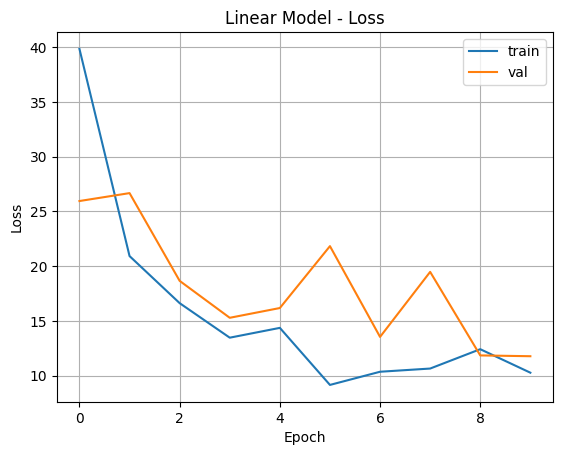

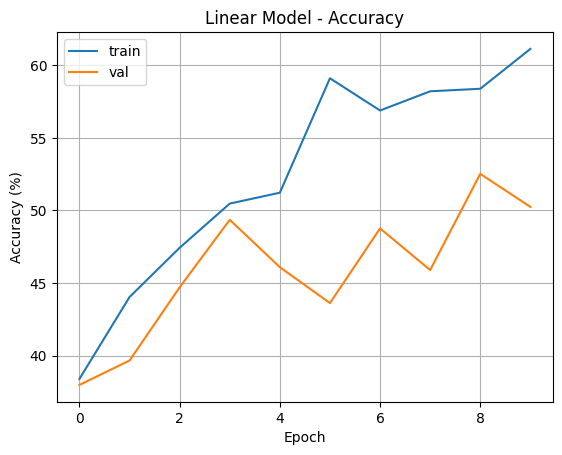

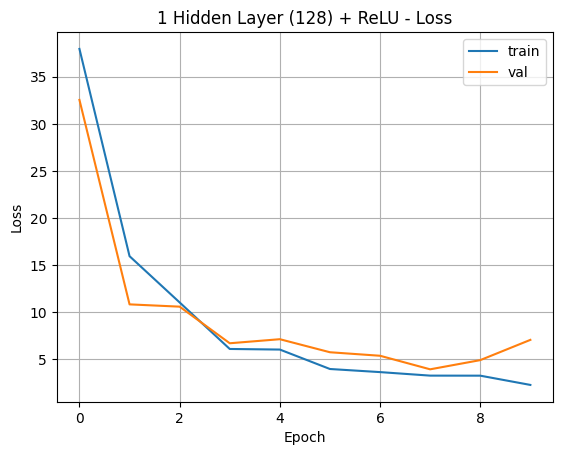

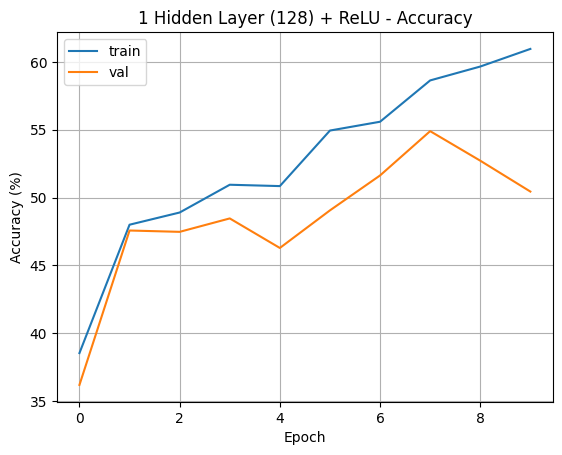

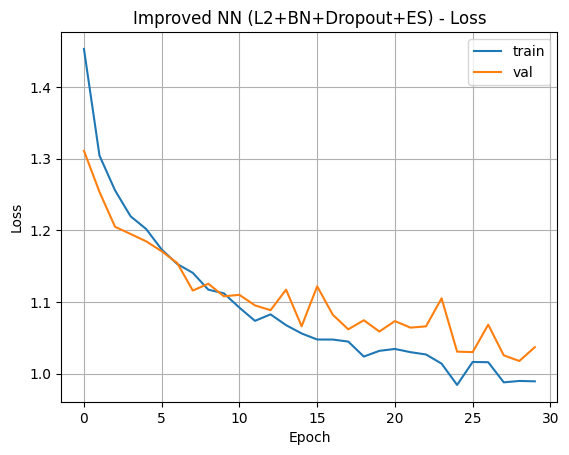

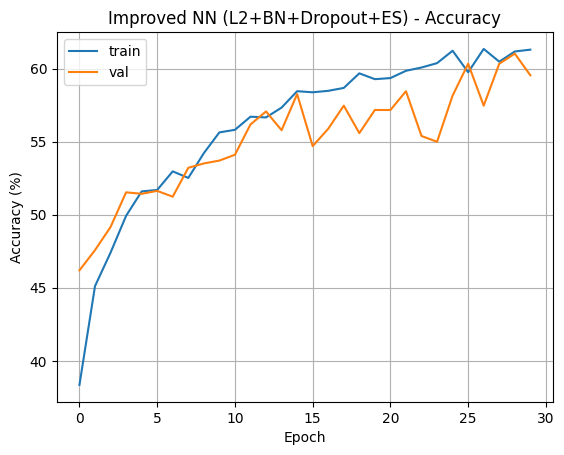

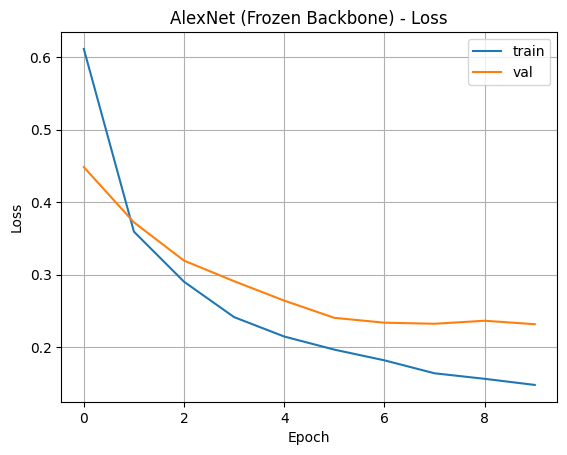

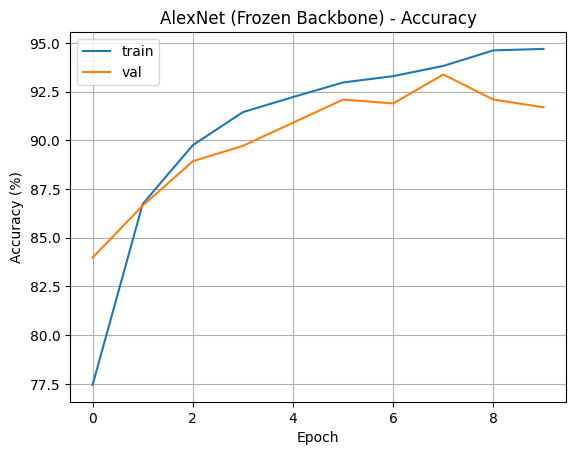

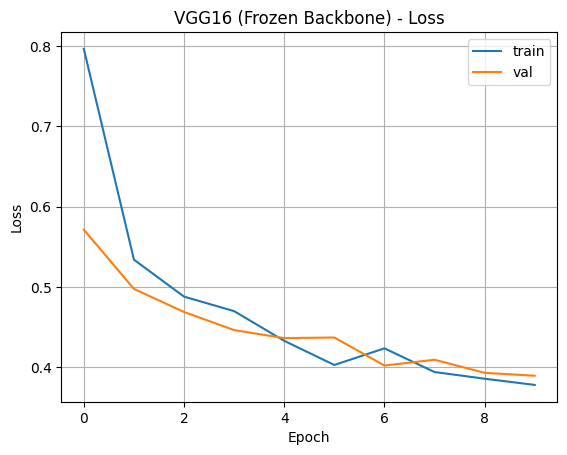

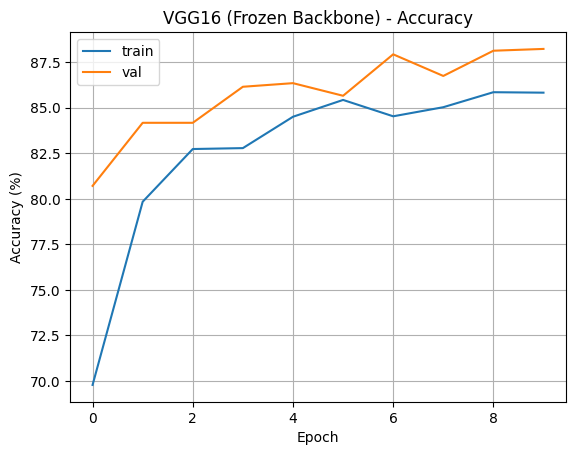

Saved figures in: outputs


In [11]:
def plot_history(hist: History, title: str, out_prefix: str):
    # Loss
    plt.figure()
    plt.plot(hist.train_loss, label="train")
    plt.plot(hist.val_loss, label="val")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} - Loss")
    plt.legend()
    plt.grid(True)
    loss_path = OUT_DIR / f"{out_prefix}_loss.png"
    plt.savefig(loss_path, dpi=200, bbox_inches="tight")
    plt.show()

    # Acc
    plt.figure()
    plt.plot(hist.train_acc, label="train")
    plt.plot(hist.val_acc, label="val")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{title} - Accuracy")
    plt.legend()
    plt.grid(True)
    acc_path = OUT_DIR / f"{out_prefix}_acc.png"
    plt.savefig(acc_path, dpi=200, bbox_inches="tight")
    plt.show()

    return str(loss_path), str(acc_path)

paths = {}
paths["linear"]  = plot_history(lin_hist, "Linear Model", "linear")
paths["relu128"] = plot_history(relu_hist, "1 Hidden Layer (128) + ReLU", "relu128")
paths["improved"]= plot_history(imp_hist, "Improved NN (L2+BN+Dropout+ES)", "improved")
paths["alexnet"] = plot_history(alex_hist, "AlexNet (Frozen Backbone)", "alexnet")
paths["vgg16"]   = plot_history(vgg_hist, "VGG16 (Frozen Backbone)", "vgg16")

print("Saved figures in:", OUT_DIR)

### Validation performance summary

Report the maximum validation accuracy, final recorded validation accuracy, minimum validation loss and number of epochs. These extrema need not occur at the same epoch.

In [12]:
def final_metrics(hist: History):
    return {
        "best_val_acc": max(hist.val_acc),
        "final_val_acc": hist.val_acc[-1],
        "best_val_loss": min(hist.val_loss),
        "epochs_ran": len(hist.val_acc)
    }

results = {
    "Linear": final_metrics(lin_hist),
    "ReLU(128)": final_metrics(relu_hist),
    "Improved": final_metrics(imp_hist),
    "AlexNet Frozen": final_metrics(alex_hist),
    "VGG16 Frozen": final_metrics(vgg_hist)
}

import pandas as pd
df = pd.DataFrame(results).T
df = df.sort_values(by="best_val_acc", ascending=False)
display(df)

df.to_csv(OUT_DIR / "comparison_table.csv", index=True)
with open(OUT_DIR / "results.json", "w") as f:
    json.dump({"results": results, "figures": paths, "classes": class_names}, f, indent=2)

print("Saved:", OUT_DIR / "comparison_table.csv", "and", OUT_DIR / "results.json")

,best_val_acc,final_val_acc,best_val_loss,epochs_ran
AlexNet Frozen,93.372898,91.691395,0.231571,10.0
VGG16 Frozen,88.229476,88.229476,0.389444,10.0
Improved,61.028684,59.545005,1.017784,30.0
ReLU(128),54.896142,50.445104,3.928170,10.0
Linear,52.522255,50.247280,11.775347,10.0


Saved: outputs/comparison_table.csv and outputs/results.json


### Comparative analysis and conclusions
| Architecture | Best validation accuracy | Final validation accuracy | Minimum validation loss |
|---|---:|---:|---:|
| Linear | 52.52% | 50.25% | 11.7753 |
| ReLU (128) | 54.90% | 50.45% | 3.9282 |
| Improved MLP | 61.03% | 59.55% | 1.0178 |
| AlexNet (frozen) | 93.37% | 91.69% | 0.2316 |
| VGG16 (frozen) | 88.23% | 88.23% | 0.3894 |

AlexNet obtains the highest recorded validation accuracy (epoch 8); both transfer-learning models outperform the dense networks. The improved MLP is the strongest dense model, but its width and training duration also differ from the baseline, so the gain cannot be attributed solely to regularization. The AlexNet–VGG16 ranking is specific to this frozen-final-layer protocol and training budget. No independent test split, repeated-seed uncertainty or isolated ablation is reported. See [analysis notes](docs/feature_selection_and_image_classification.md).